In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from galaxy_sidm.io import load_config, load_flat
from galaxy_sidm.mock.barolo import rings_file
from galaxy_sidm.mock.tables import MODELS, assemble, flat_rings, vcirc_at, vcirc_curves
from galaxy_sidm.viz import legend_entries, panel_grid, running_median

plt.rcParams.update({
    # paper font: bundled Computer Modern (cmr10) -- do NOT use usetex here
    "font.family": "serif",
    "font.serif": ["cmr10", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "axes.formatter.use_mathtext": True,
    "axes.unicode_minus": False,
    # legibility
    "axes.labelsize": 19,
    "axes.titlesize": 19,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "legend.fontsize": 14,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
    "xtick.major.size": 5.5, "ytick.major.size": 5.5,
})

cfg = load_config(None)
PROC = Path(cfg["paths"]["scratch_processed"])
MARTINI = PROC.parent / "martini"
colors = cfg["model_colors"]
flat_tol, retry_tol = 0.05, 0.10
mstar_step, n_min = 0.25, 5
ratio_ylim = (0.4, 1.4)
n_mass_bins = 3
x_grid = np.arange(0.025, 1.0, 0.05)

In [2]:
#per galaxy of the final sample with a successful final fit: BBarolo rings, particle rings, v_circ, MORDOR Mstar
gals, kin, row_of, curves = [], {}, {}, {}
for r in assemble(cfg):
    key, sub = (r["model"], r["snap"]), r["sub_id"]
    if key not in kin:
        kin[key], _ = load_flat(PROC / "gas_kinematics" / f"gas_kinematics_{key[0]}_{key[1]:03d}.hdf5")
        row_of[key] = {int(s): j for j, s in enumerate(kin[key]["halo_ids"])}
        curves[key] = vcirc_curves(cfg, *key)
    a, i = kin[key], row_of[key][sub]
    n = int(a["n_rings"][i])
    edges = a["ring_edges"][:n + 1]
    R_b, vrot = np.loadtxt(rings_file(MARTINI / f"z{r['z']:g}" / r["model"] / f"gal_{sub:06d}" / "bbarolo"),
                           usecols=(0, 2), ndmin=2).T
    sigma2 = sum(a[f"ring_sigma_{c}"][i][:n] ** 2 for c in ("vR", "vphi", "vz"))
    gals.append(dict(model=r["model"], z=r["z"], sub=sub, log_mstar=np.log10(r["Mstar"]), R_95=a["R_95"][i],
                     R_b=R_b, vrot=vrot, vc_b=vcirc_at(R_b, *curves[key][sub]),
                     R_p=0.5 * (edges[1:] + edges[:-1]), vc_p=a["ring_vcirc"][i][:n], vphi=a["ring_vphi"][i][:n],
                     vR=a["ring_vR"][i][:n], vz=a["ring_vz"][i][:n], sigma=np.sqrt(sigma2 / 3)))
print(len(gals), "galaxies")

3698 galaxies


In [3]:
#ratios on the flat rings (flat_rings, as the TFR); v_phi there is the particle profile interpolated at BBarolo's radii
for g in gals:
    used, rule = flat_rings(g["vrot"], flat_tol, retry_tol)
    g["flat"] = rule is not None
    if g["flat"]:
        v_rot, v_c = g["vrot"][used].mean(), g["vc_b"][used].mean()
        v_phi = np.interp(g["R_b"][used], g["R_p"], g["vphi"], left=np.nan, right=np.nan).mean()
        g.update(rot_circ=v_rot / v_c, phi_circ=v_phi / v_c, rot_phi=v_rot / v_phi)
zs = sorted({g["z"] for g in gals})
for model in MODELS:
    for z in zs:
        sel = [g for g in gals if g["model"] == model and g["z"] == z]
        if sel:
            flat = [g for g in sel if g["flat"]]
            print(f"{model} z = {z:g}: {len(sel)} galaxies, {len(flat)} with a flat part, "
                  f"{sum(bool(np.isfinite(g['phi_circ'])) for g in flat)} of them with v_phi on all their flat rings")

CDM z = 0: 372 galaxies, 363 with a flat part, 359 of them with v_phi on all their flat rings
CDM z = 0.5: 388 galaxies, 379 with a flat part, 379 of them with v_phi on all their flat rings
CDM z = 1: 320 galaxies, 308 with a flat part, 308 of them with v_phi on all their flat rings
CDM z = 2: 174 galaxies, 143 with a flat part, 143 of them with v_phi on all their flat rings
CDM z = 3: 55 galaxies, 43 with a flat part, 42 of them with v_phi on all their flat rings
CDM z = 4: 12 galaxies, 7 with a flat part, 7 of them with v_phi on all their flat rings
CDM z = 5: 1 galaxies, 0 with a flat part, 0 of them with v_phi on all their flat rings
SIDM1 z = 0.5: 414 galaxies, 401 with a flat part, 401 of them with v_phi on all their flat rings
SIDM1 z = 1: 379 galaxies, 353 with a flat part, 350 of them with v_phi on all their flat rings
SIDM1 z = 2: 202 galaxies, 172 with a flat part, 172 of them with v_phi on all their flat rings
SIDM1 z = 3: 66 galaxies, 45 with a flat part, 45 of them with v

$v_{\rm rot}/v_{\rm circ}$: 1 galaxies outside the plotted range (0.4, 1.4)


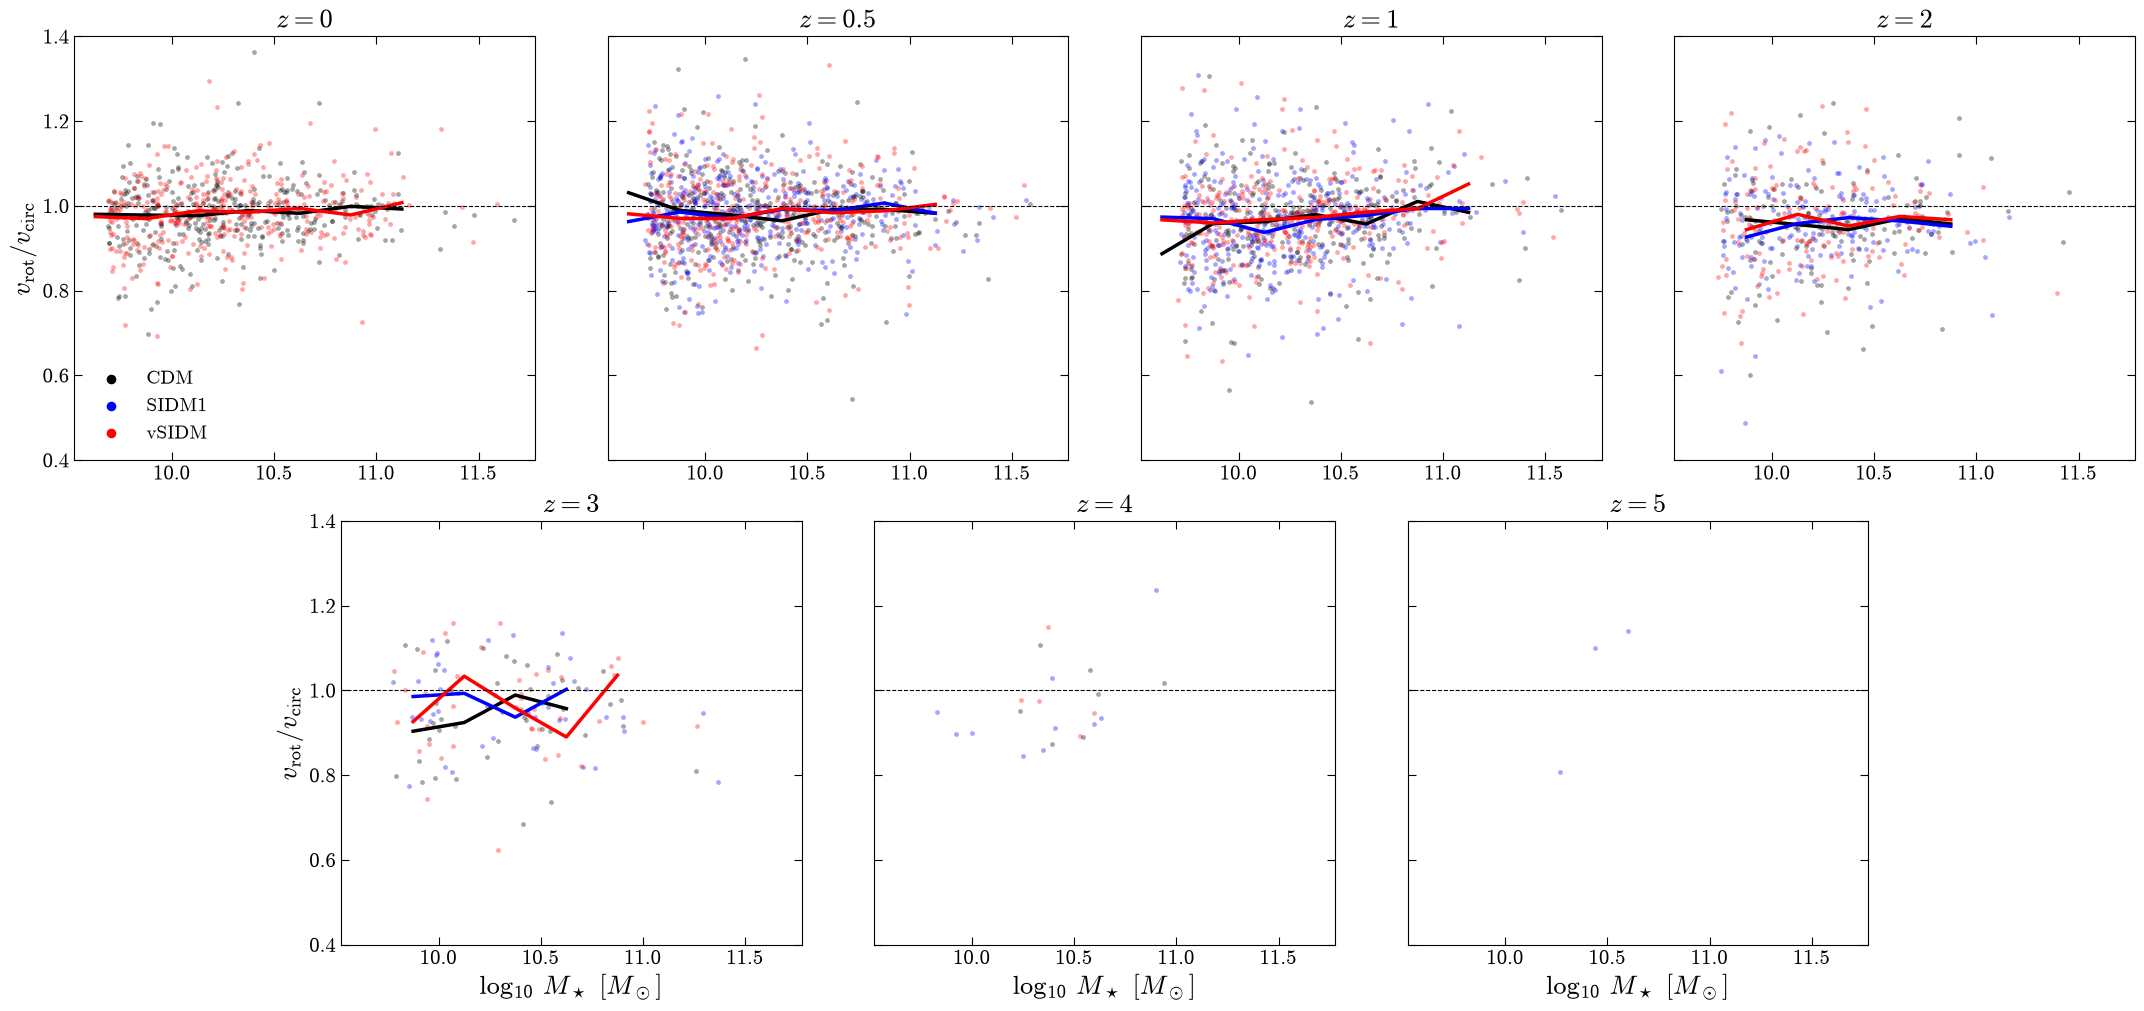

$v_\phi/v_{\rm circ}$: 0 galaxies outside the plotted range (0.4, 1.4)


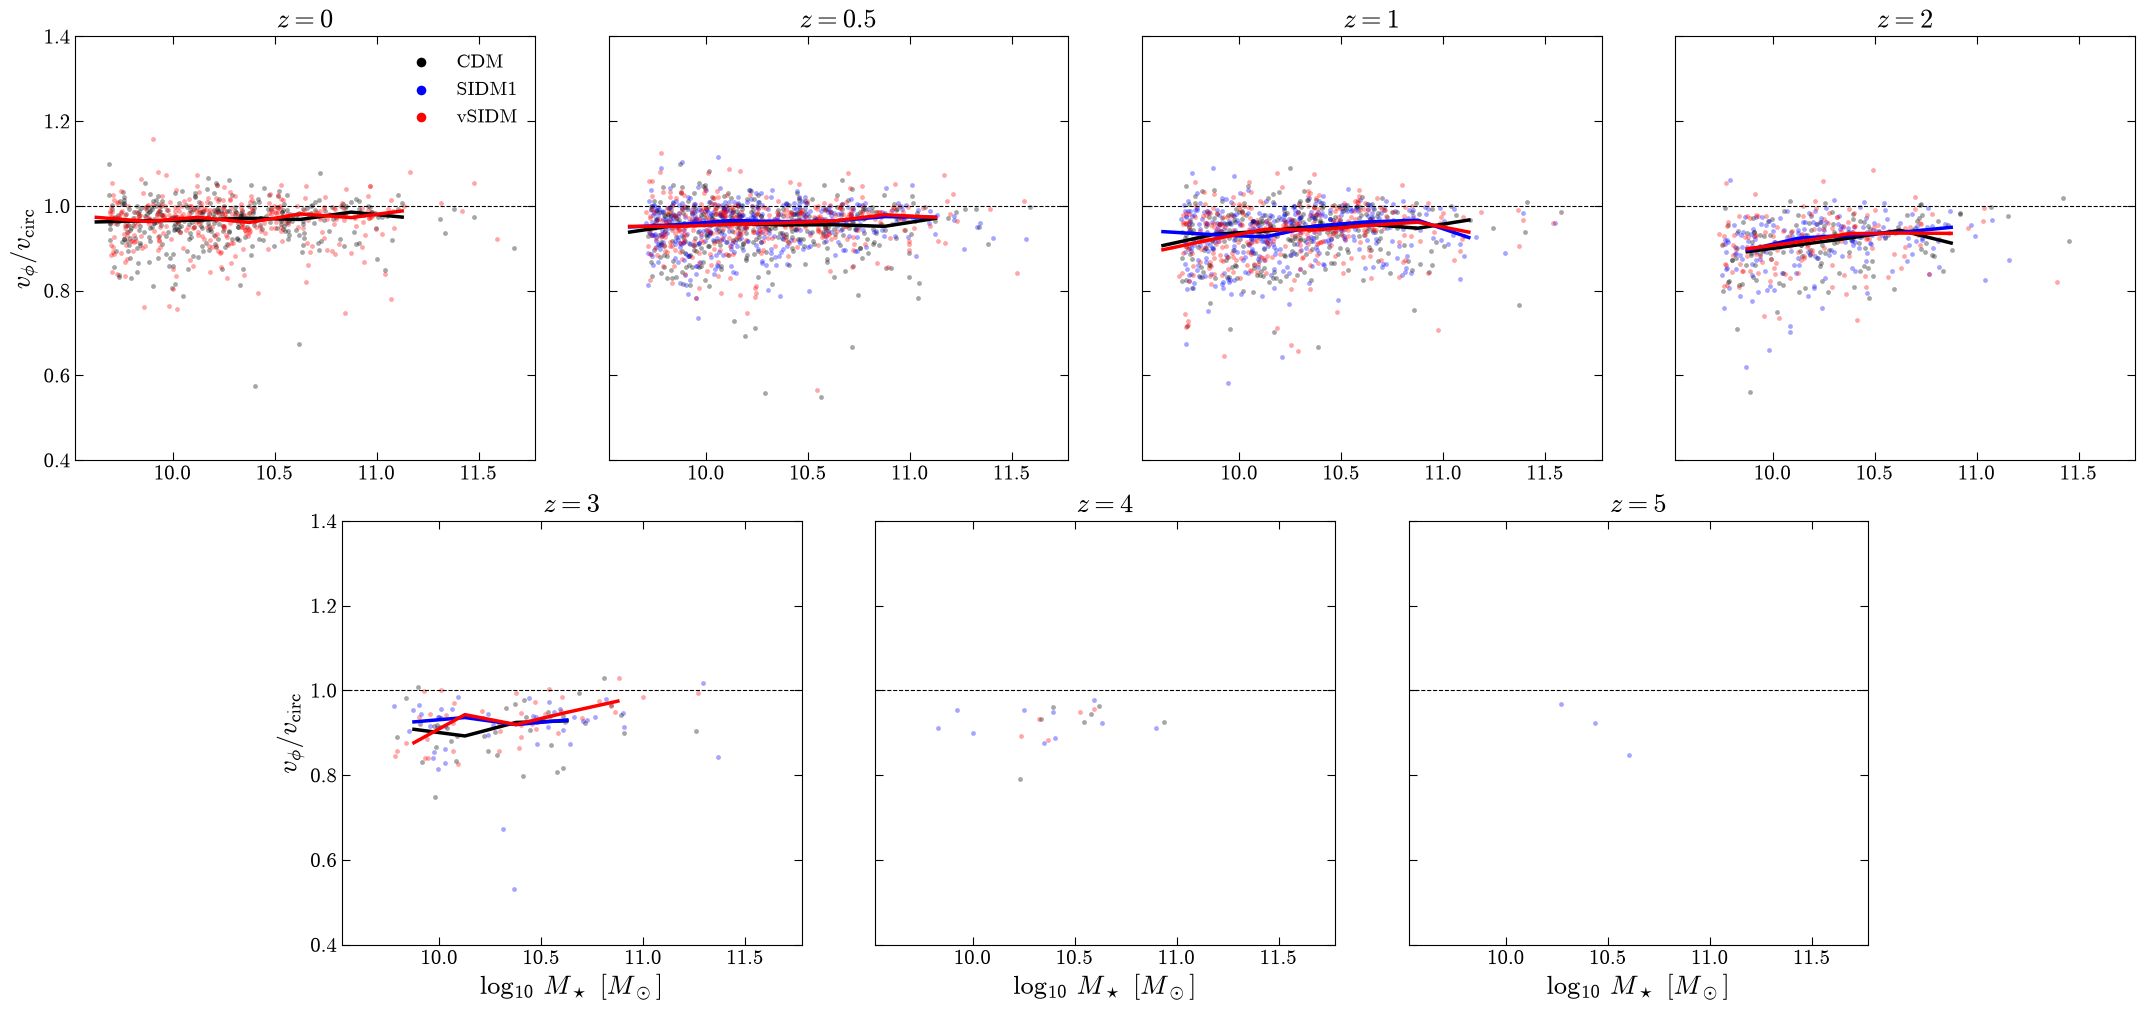

$v_{\rm rot}/v_\phi$: 28 galaxies outside the plotted range (0.4, 1.4)


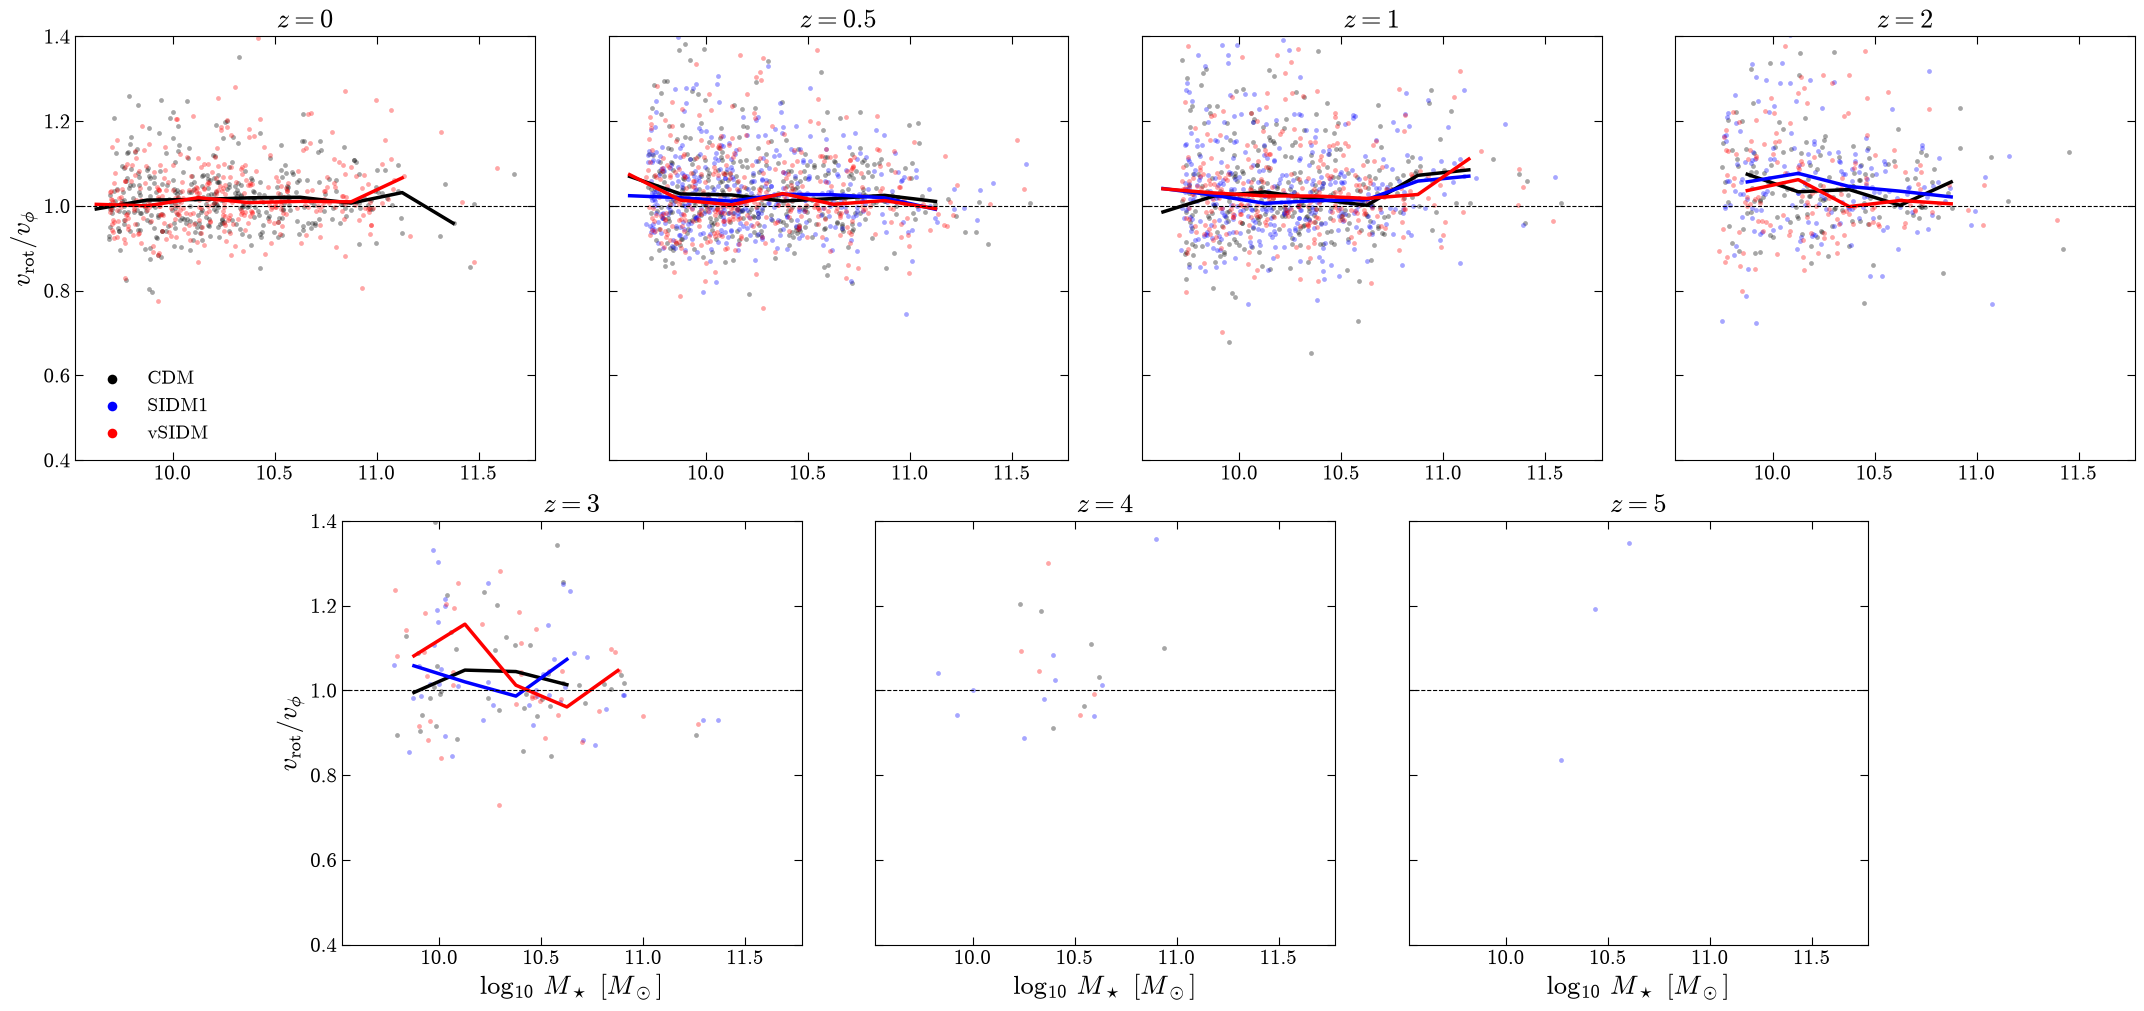

In [4]:
#ratios against MORDOR Mstar, one panel per redshift; lines: running median per model
ratio_labels = {"rot_circ": r"$v_{\rm rot}/v_{\rm circ}$", "phi_circ": r"$v_\phi/v_{\rm circ}$",
                "rot_phi": r"$v_{\rm rot}/v_\phi$"}
flat = [g for g in gals if g["flat"]]
lm_all = np.array([g["log_mstar"] for g in flat])
bins = np.arange(np.floor(lm_all.min() / mstar_step) * mstar_step, lm_all.max() + mstar_step, mstar_step)
for key, label in ratio_labels.items():
    outside = sum(bool(np.isfinite(g[key]) and not ratio_ylim[0] <= g[key] <= ratio_ylim[1]) for g in flat)
    print(f"{label}: {outside} galaxies outside the plotted range {ratio_ylim}")
    fig, axes, bottom, left = panel_grid(len(zs), (16 / 3, 5), constrained_layout=True)
    for ax, z in zip(axes, zs, strict=True):
        for model in MODELS:
            sel = [g for g in flat if g["model"] == model and g["z"] == z and np.isfinite(g[key])]
            if not sel:
                continue
            x, y = np.array([g["log_mstar"] for g in sel]), np.array([g[key] for g in sel])
            ax.scatter(x, y, s=12, color=colors[model], alpha=0.35, lw=0, rasterized=True, label=model)
            cen, med = running_median(x, y, bins, n_min)
            ax.plot(cen, med, color=colors[model], lw=2.5)
        ax.axhline(1, color="k", ls="--", lw=0.8)
        ax.set_ylim(ratio_ylim)
        ax.set_title(rf"$z = {z:g}$")
    for ax in bottom:
        ax.set_xlabel(r"$\log_{10}\,M_\star\ [M_\odot]$")
    for ax in left:
        ax.set_ylabel(label)
    leg = axes[0].legend(*legend_entries(axes, MODELS), frameon=False, markerscale=2)
    for h in leg.legend_handles:
        h.set_alpha(1)
    plt.show()

log Mstar bins: [ 9.68 10.03 10.39 11.67]


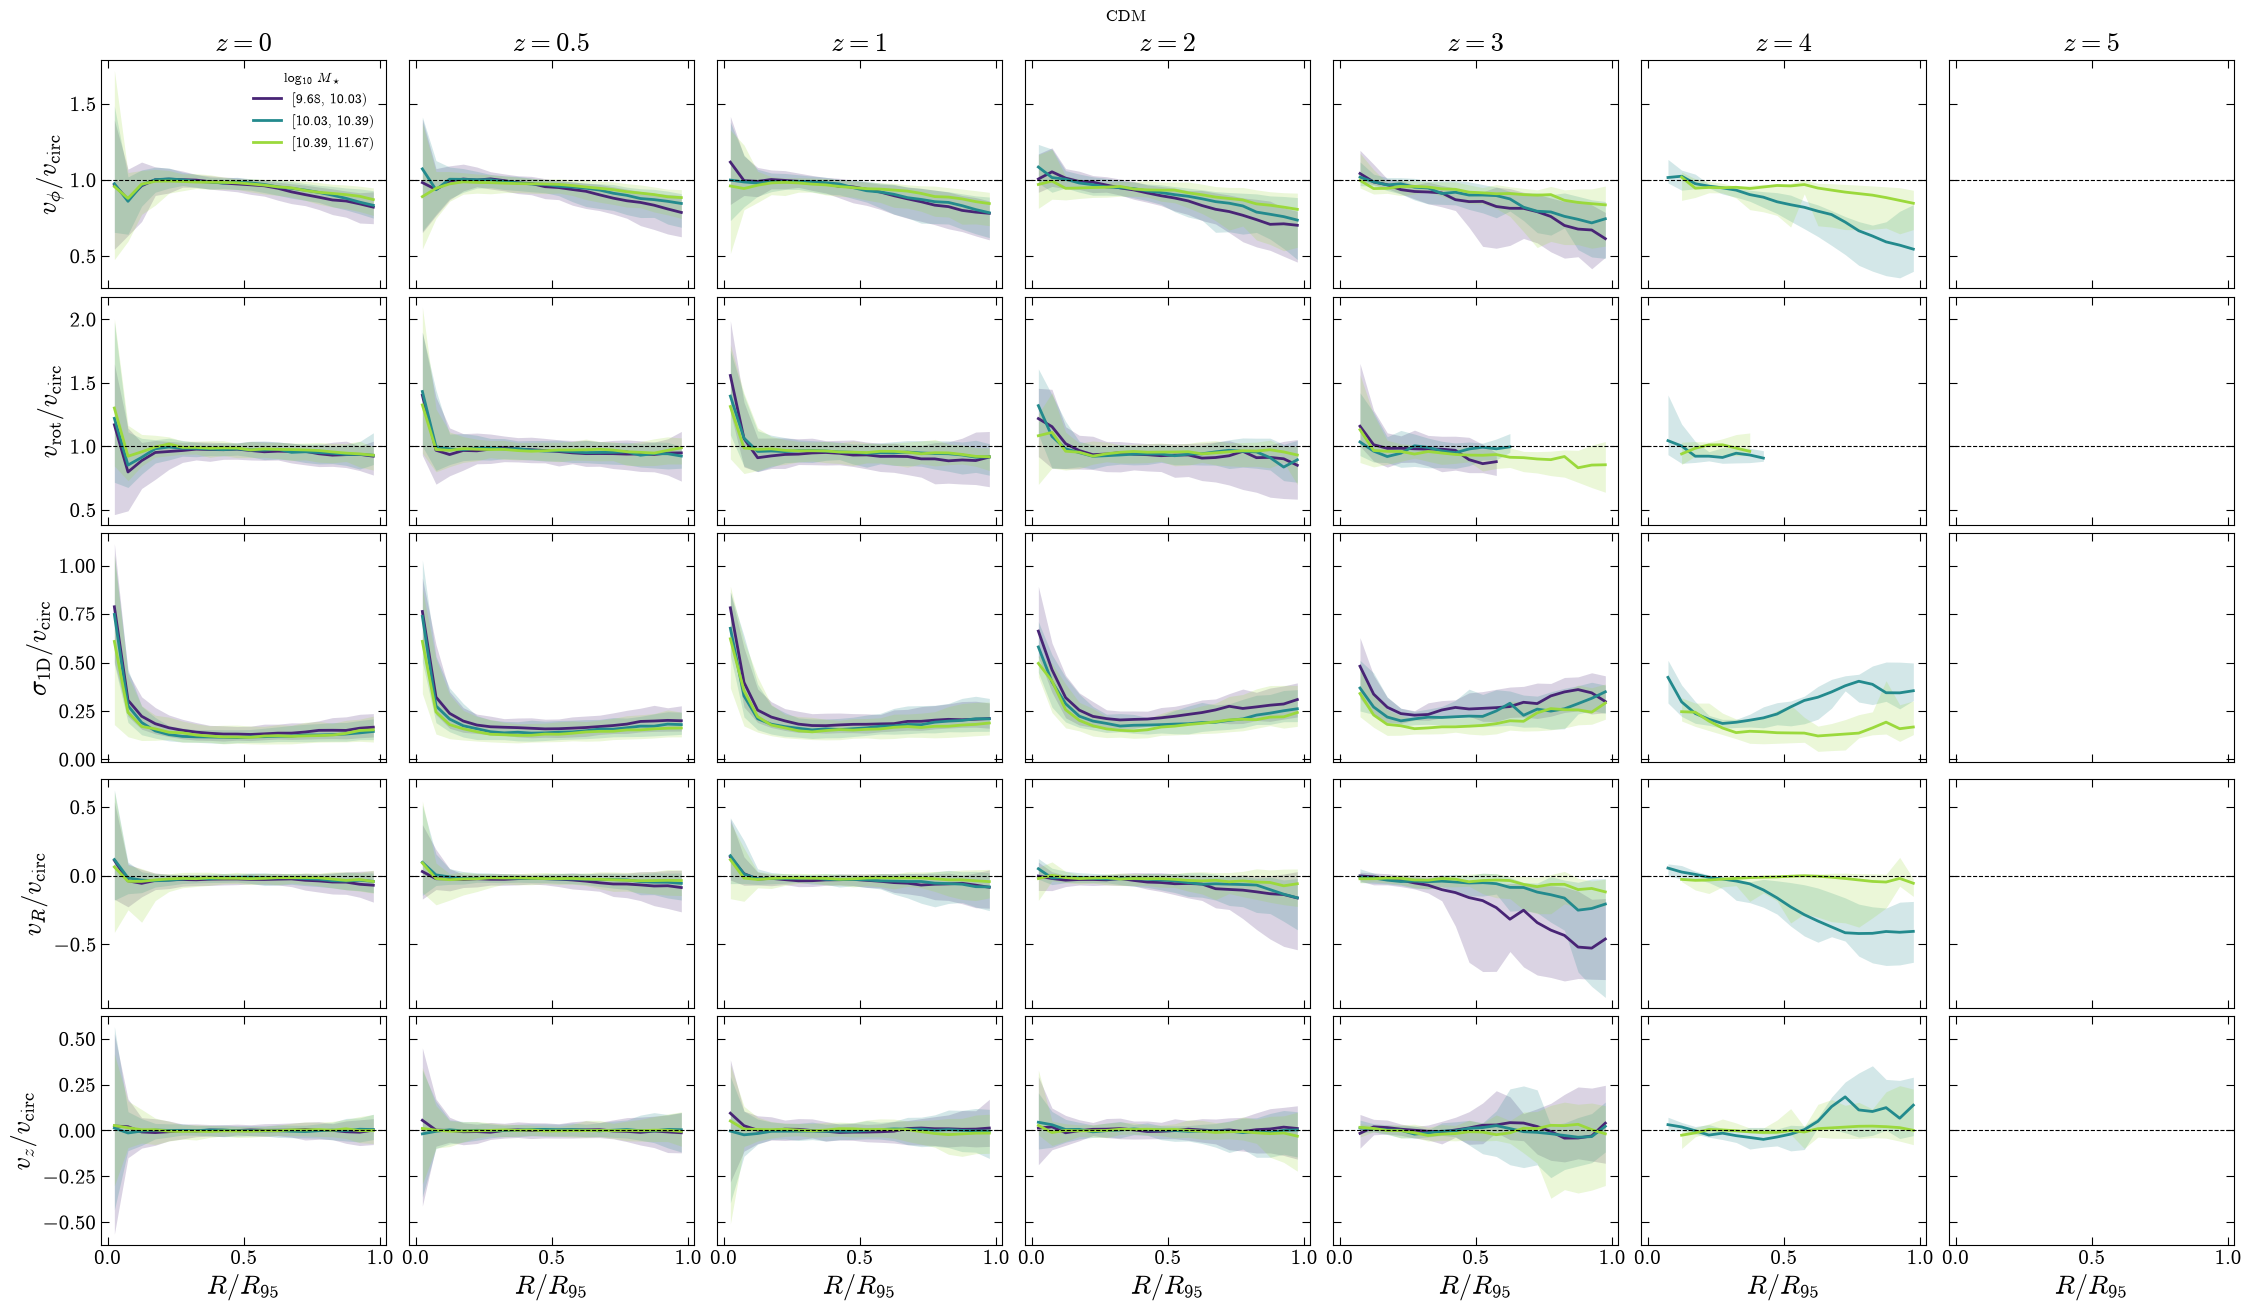

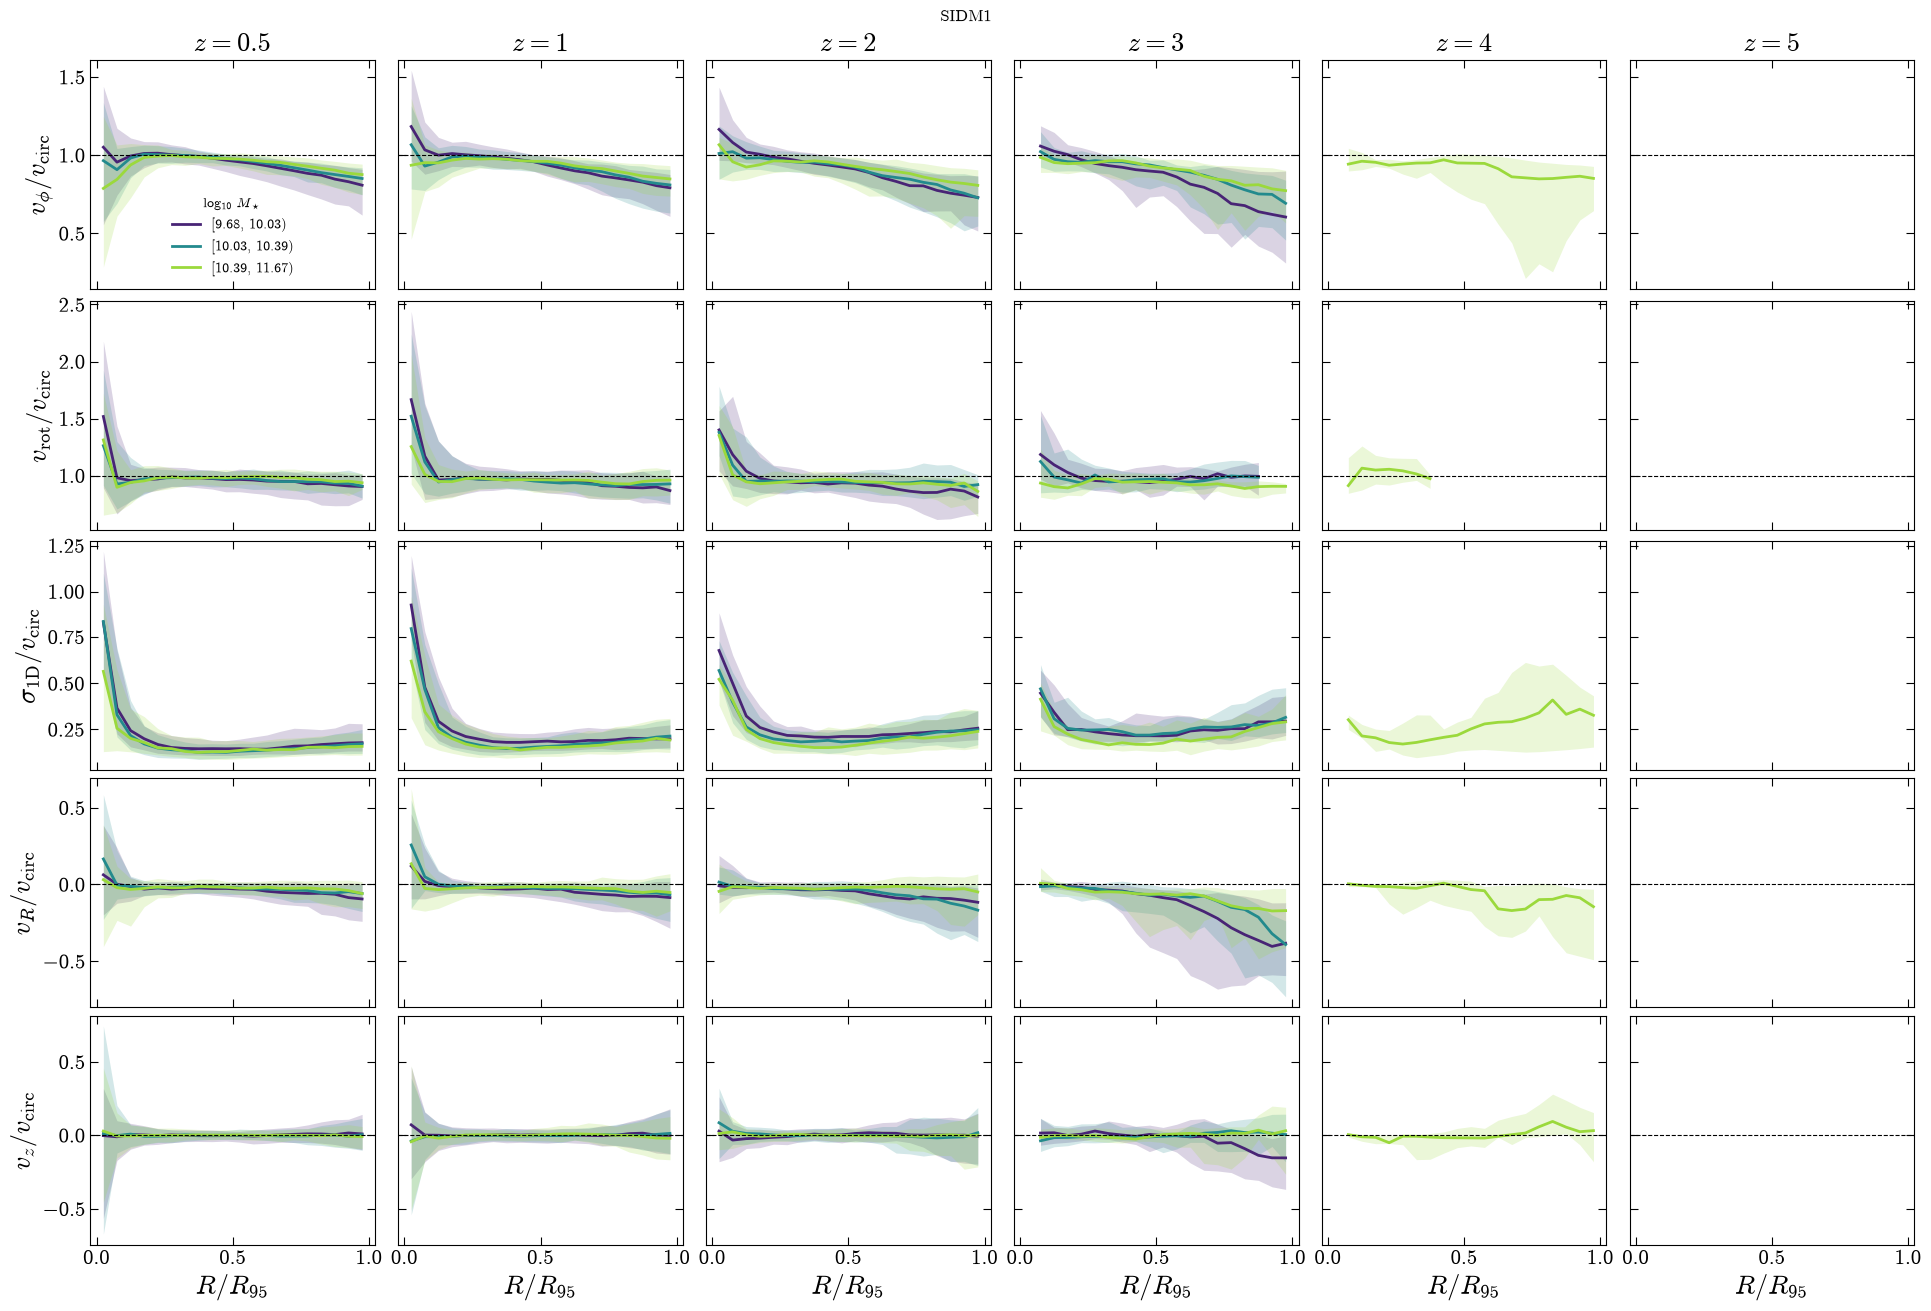

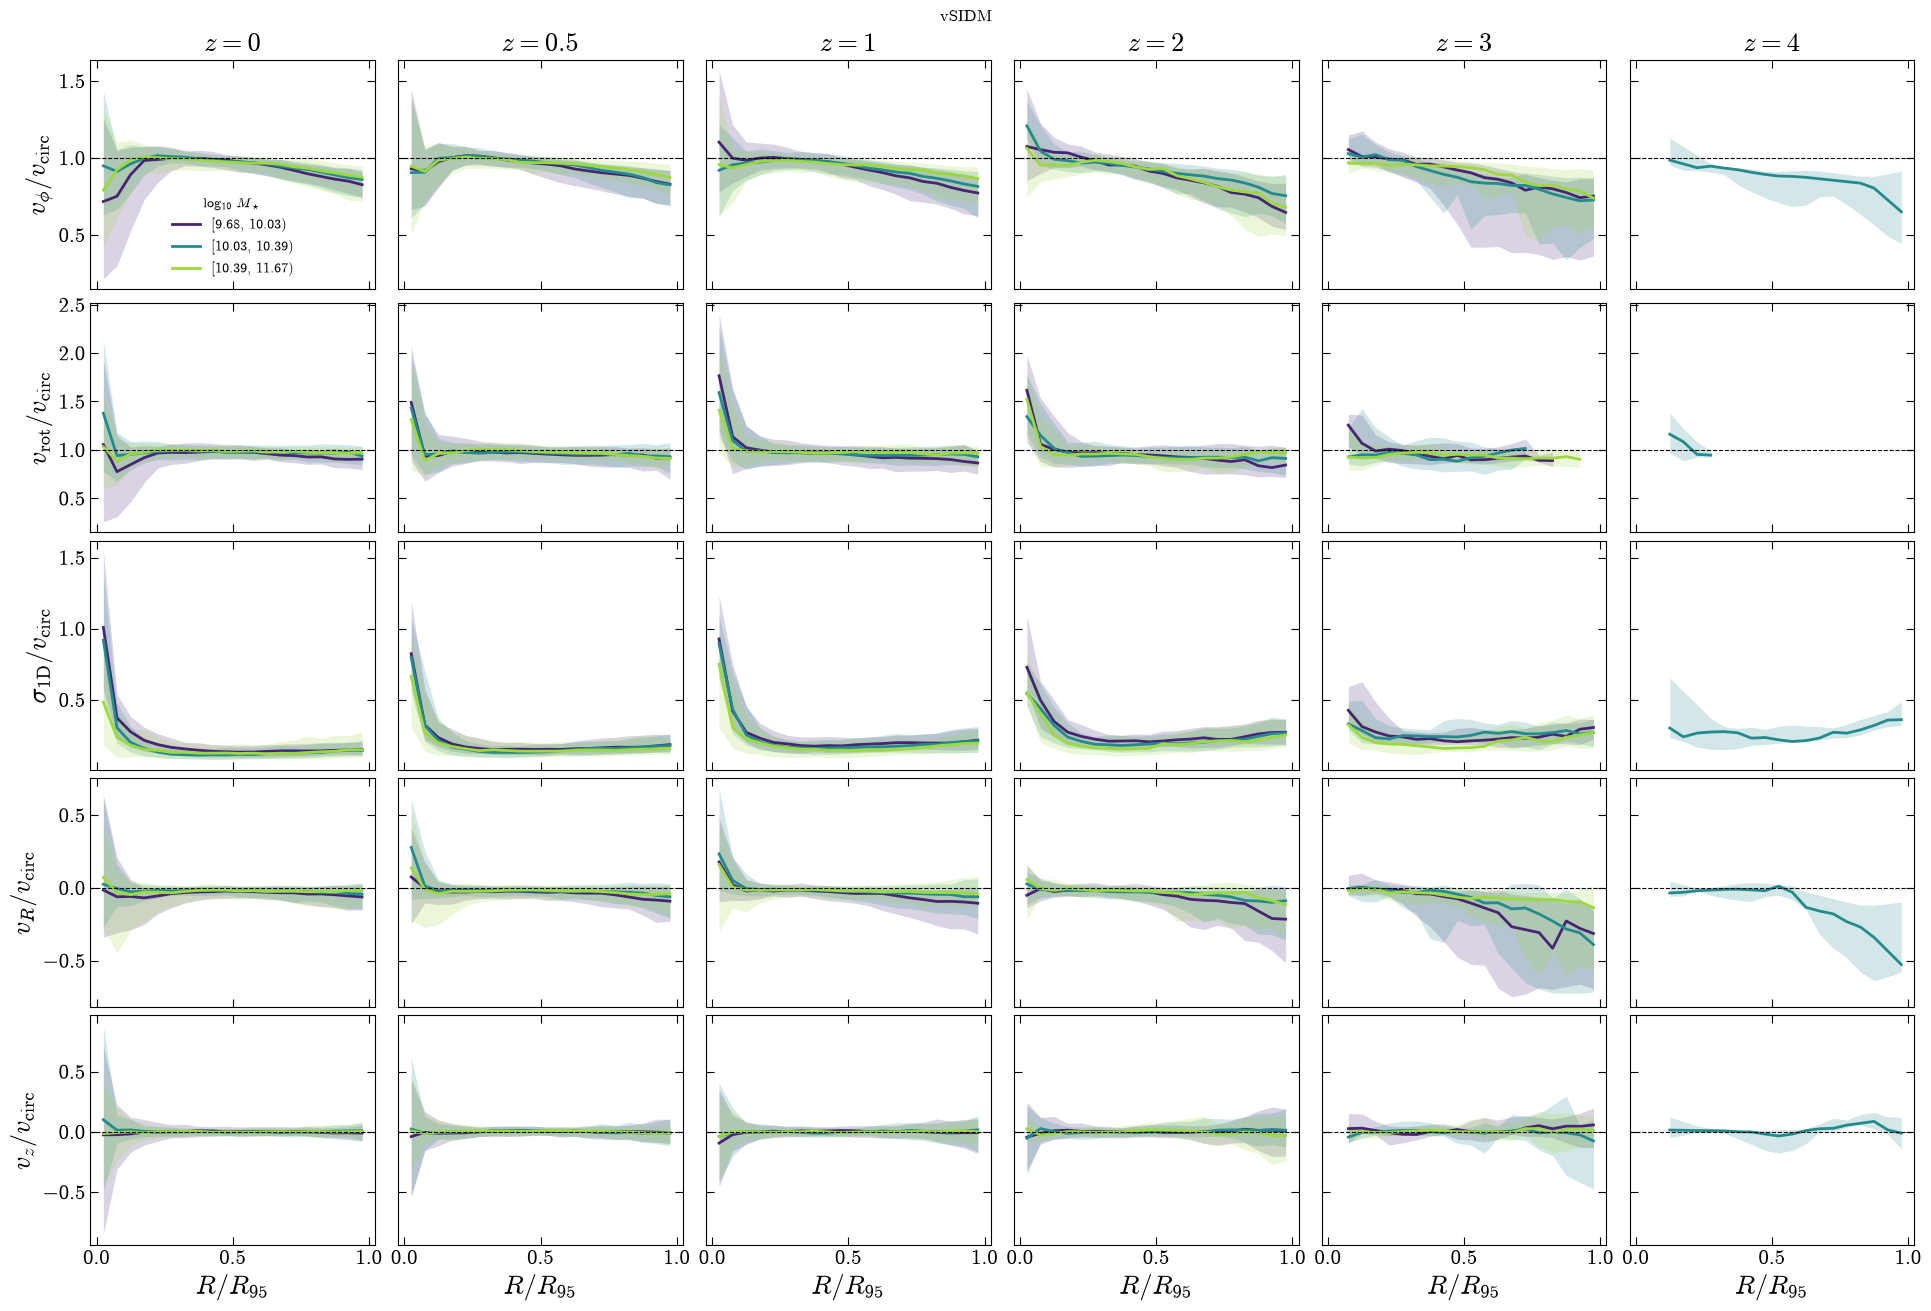

In [5]:
#median profiles against R / R_95 in thirds of Mstar (all galaxies), 16-84th percentile band; one figure per model
mass_edges = np.quantile([g["log_mstar"] for g in gals], np.linspace(0, 1, n_mass_bins + 1))
mass_edges[-1] += 1e-9
mass_colors = plt.get_cmap("viridis")(np.linspace(0.1, 0.85, n_mass_bins))
print("log Mstar bins:", np.round(mass_edges, 2))
profiles = {r"$v_\phi/v_{\rm circ}$": ("R_p", "vphi", "vc_p", 1), r"$v_{\rm rot}/v_{\rm circ}$": ("R_b", "vrot", "vc_b", 1),
            r"$\sigma_{\rm 1D}/v_{\rm circ}$": ("R_p", "sigma", "vc_p", None), r"$v_R/v_{\rm circ}$": ("R_p", "vR", "vc_p", 0),
            r"$v_z/v_{\rm circ}$": ("R_p", "vz", "vc_p", 0)}
for model in MODELS:
    zs_m = [z for z in zs if any(g["model"] == model and g["z"] == z for g in gals)]
    fig, axes = plt.subplots(len(profiles), len(zs_m), figsize=(3.2 * len(zs_m), 2.6 * len(profiles)),
                             sharex=True, sharey="row", squeeze=False, constrained_layout=True)
    for col, z in zip(axes.T, zs_m):
        col[0].set_title(rf"$z = {z:g}$")
        for b in range(n_mass_bins):
            sel = [g for g in gals if g["model"] == model and g["z"] == z
                   and mass_edges[b] <= g["log_mstar"] < mass_edges[b + 1]]
            for ax, (rkey, vkey, ckey, ref) in zip(col, profiles.values()):
                ys = np.array([np.interp(x_grid, g[rkey] / g["R_95"], g[vkey] / g[ckey], left=np.nan, right=np.nan)
                               for g in sel]).reshape(-1, len(x_grid))
                ok = np.sum(np.isfinite(ys), axis=0) >= n_min
                if ok.any():
                    lo, med, hi = np.nanpercentile(ys[:, ok], [16, 50, 84], axis=0)
                    ax.plot(x_grid[ok], med, color=mass_colors[b], lw=2,
                            label=f"[{mass_edges[b]:.2f}, {mass_edges[b + 1]:.2f})")
                    ax.fill_between(x_grid[ok], lo, hi, color=mass_colors[b], alpha=0.2, lw=0)
        for ax, (_, _, _, ref) in zip(col, profiles.values()):
            if ref is not None:
                ax.axhline(ref, color="k", ls="--", lw=0.8)
    for ax, label in zip(axes[:, 0], profiles):
        ax.set_ylabel(label)
    for ax in axes[-1]:
        ax.set_xlabel(r"$R/R_{95}$")
    fig.suptitle(model)
    axes[0, 0].legend(*legend_entries(axes.flat), title=r"$\log_{10}\,M_\star$", frameon=False, fontsize=10)
    plt.show()